# Shor's Algorithm — Factoring 15, Start to Finish

Shor's algorithm factors a number N by turning factoring into a **period-finding** problem: pick a number a, and find how often aˣ mod N repeats. Once you know that period r, ordinary classical arithmetic (gcd) usually hands you a real factor of N.

**What this notebook does:**
1. Run the classical setup and period-finding for N = 15, a = 7 — the textbook example
2. Show *why* finding the period is the hard part, and what a quantum computer actually does differently
3. Use Qiskit's real Quantum Fourier Transform to demonstrate the interference pattern that makes period-finding fast on a quantum computer
4. Extract the factors, and check every valid choice of a for N = 15

In [1]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np

N = 15

## Step 1 — Classical Setup

Pick a number a with 1 < a < N that shares no common factor with N (gcd(a, N) = 1). If it did share a factor, that factor would already solve the problem — no quantum computer needed.

In [2]:
import math

def gcd(a, b):
    return math.gcd(a, b)

a = 7
print(f'a = {a}, gcd(a, N) = {gcd(a, N)}')  # must be 1 for a to be a valid choice

a = 7, gcd(a, N) = 1


## Step 2 — Finding the Period, Classically

Before touching anything quantum, let's see *what* we're looking for: the sequence aˣ mod N, and how quickly it repeats. This is exactly what the live slide computes.

Sequence of 7^x mod 15: [1, 7, 4, 13, 1]
Period r = 4


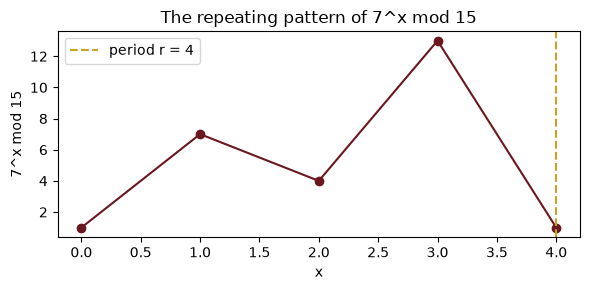

In [3]:
def find_period(a, n, max_x=12):
    seq = [1]
    for x in range(1, max_x + 1):
        v = pow(a, x, n)
        seq.append(v)
        if v == 1:
            return x, seq
    return None, seq

r, seq = find_period(a, N)
print(f'Sequence of {a}^x mod {N}:', seq)
print(f'Period r = {r}')

plt.figure(figsize=(6, 3))
plt.plot(range(len(seq)), seq, 'o-', color='#6A171F')
plt.axvline(r, color='#C9A227', linestyle='--', label=f'period r = {r}')
plt.xlabel('x')
plt.ylabel(f'{a}^x mod {N}')
plt.title(f'The repeating pattern of {a}^x mod {N}')
plt.legend()
plt.tight_layout()
plt.show()

## Step 3 — Why This Needs a Quantum Computer

Checking the sequence one value at a time (what we just did) is exactly what makes this *classically* slow for large N — the period can be enormous, and there's no shortcut to finding it by direct search.

A quantum computer does something fundamentally different: it builds a **superposition** of aˣ mod N for every x *at once*, using one register to hold x and a second register to hold the result. Measuring that state directly would just give one random value — no better than checking by hand. The trick is to apply the **Quantum Fourier Transform (QFT)** to the x-register first. Because the underlying state is periodic with period r, the QFT concentrates measurement probability onto just a handful of specific outcomes — multiples of Q/r, where Q is the size of the register — instead of spreading it evenly across everything.

We can demonstrate that interference effect directly, using Qiskit's real QFT, without needing the full modular-exponentiation circuit: prepare the exact periodic state the algorithm would produce for our period r = 4, then apply the QFT and look at where the probability lands.

Q = 16, r = 4 -> periodic register positions: [0, 4, 8, 12]


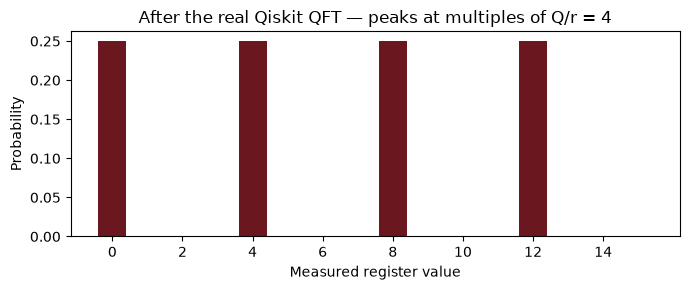

Peaks at: [0, 4, 8, 12] — exactly the multiples of 4


In [4]:
Q_BITS = 4
Q = 2 ** Q_BITS  # 16 possible register values

# The state a quantum period-finding circuit produces before the QFT is an equal
# superposition over every multiple of r, up to Q: |0> + |r> + |2r> + ... (normalized).
periodic_positions = list(range(0, Q, r))
print(f'Q = {Q}, r = {r} -> periodic register positions:', periodic_positions)

amplitude = 1 / np.sqrt(len(periodic_positions))
state = np.zeros(Q, dtype=complex)
for pos in periodic_positions:
    state[pos] = amplitude

qc = QuantumCircuit(Q_BITS)
qc.initialize(state, range(Q_BITS))
qc.append(QFTGate(Q_BITS), range(Q_BITS))

final = Statevector(qc)
probs = final.probabilities()

plt.figure(figsize=(7, 3))
plt.bar(range(Q), probs, color='#6A171F')
plt.xlabel('Measured register value')
plt.ylabel('Probability')
plt.title(f'After the real Qiskit QFT — peaks at multiples of Q/r = {Q // r}')
plt.xticks(range(0, Q, 2))
plt.tight_layout()
plt.show()

peak_positions = [i for i, p in enumerate(probs) if p > 0.01]
print('Peaks at:', peak_positions, '— exactly the multiples of', Q // r)

The peaks land exactly where the math predicts: at 0, 4, 8, and 12 — multiples of Q/r = 16/4 = 4. Measuring this register and doing a little classical post-processing on the result recovers r — and that read-out is the one step with no known fast classical equivalent.

*(This demonstrates the QFT's role on the exact state the full algorithm produces for this r. The full circuit also needs a controlled modular-exponentiation step to build that periodic state from scratch — real, but more involved circuitry that doesn't change the interference argument above.)*

## Step 4 — From Period to Factor

Once r is known (here, from Step 2), plain classical arithmetic finishes the job — no quantum computer needed for this part.

In [5]:
def extract_factors(a, r, n):
    if r is None or r % 2 != 0:
        return None  # odd period -> this attempt fails, pick a new a
    half = pow(a, r // 2, n)
    if half == n - 1:
        return None  # a^(r/2) = -1 (mod n) -> trivial factors only, pick a new a
    f1, f2 = gcd(half - 1, n), gcd(half + 1, n)
    return f1, f2

factors = extract_factors(a, r, N)
print(f'a = {a}, r = {r} -> factors: {factors}')
print(f'Check: {factors[0]} * {factors[1]} = {factors[0] * factors[1]}')

a = 7, r = 4 -> factors: (3, 5)
Check: 3 * 5 = 15


## Step 5 — Every Valid Choice of a, for N = 15

Not every a succeeds — some give an odd period, and a = 14 specifically gives a^(r/2) ≡ −1 (mod 15), which only yields the trivial factors 1 and 15. This is exactly why the algorithm is probabilistic: if one a fails, you simply try another.

In [6]:
valid_a = [x for x in range(2, N) if gcd(x, N) == 1]
print(f'Valid choices of a for N = {N}: {valid_a}\n')

for candidate in valid_a:
    r_candidate, _ = find_period(candidate, N)
    factors = extract_factors(candidate, r_candidate, N)
    outcome = f'factors {factors}' if factors else 'fails (try another a)'
    print(f'a = {candidate:2d}  r = {r_candidate}  ->  {outcome}')

Valid choices of a for N = 15: [2, 4, 7, 8, 11, 13, 14]

a =  2  r = 4  ->  factors (3, 5)
a =  4  r = 2  ->  factors (3, 5)
a =  7  r = 4  ->  factors (3, 5)
a =  8  r = 4  ->  factors (3, 5)
a = 11  r = 2  ->  factors (5, 3)
a = 13  r = 4  ->  factors (3, 5)
a = 14  r = 2  ->  fails (try another a)


## Recap

- Factoring N = 15 was turned into finding the period of aˣ mod 15 for a chosen a
- The period-finding step is the one genuinely quantum part — a quantum computer builds a superposition over every x and uses the **Quantum Fourier Transform** to concentrate probability onto the period, demonstrated above with Qiskit's real QFT
- Classical arithmetic (gcd) turns that period into an actual factor — 6 out of 7 valid choices of a succeed for N = 15, and the one failure (a = 14) just means trying again
- This is why RSA encryption is considered broken *in principle* by a large enough fault-tolerant quantum computer, and why post-quantum cryptography is already being standardized